# Image Classification: จำแนกสายพันธุ์สุนัขและแมว 37 สายพันธุ์
**ชุดข้อมูล:** The Oxford-IIIT Pet Dataset  **แนวทาง:** Transfer learning (CNN ที่ฝึกบน ImageNet เป็นตัวสกัดคุณลักษณะ) + ตัวจำแนกของ scikit-learn

**ผู้จัดทำ** (เรียงตามรหัสนิสิต)

| รหัสนิสิต | ชื่อ–นามสกุล |
|---|---|
| 6630300866 | นาย สกลภัทร ภิญโญ |
| 6730300281 | นาย นันทพัฒน์ วรรณลักษณ์ |
| 6730300591 | นาย ศุภวิชญ์ ไชยานุศักดิ์ |
| 6730300779 | นาย ธรรศธรณ์ เจียมตน |
| 6730300850 | นาย พัฒนเดช มะหิเมือง |

> รัน notebook นี้จากโฟลเดอร์ `image_classification/notebooks/` ตามลำดับจากบนลงล่าง
> (ต้องเตรียมข้อมูลด้วย `scripts/prepare_data.py` ก่อน — ดู `data/README.md`)

## 1. ปัญหาและเป้าหมายของโครงการ

**ปัญหา:** ผู้เลี้ยงสัตว์ ผู้ที่จะรับเลี้ยง หรือสถานพักพิงสัตว์ มักไม่แน่ใจว่าสุนัขหรือแมวที่เห็นเป็นสายพันธุ์อะไร
ทั้งที่สายพันธุ์บอกข้อมูลสำคัญ เช่น ขนาดตัวเมื่อโต นิสัย การดูแลขน และโรคที่พบบ่อยในสายพันธุ์นั้น
หลายสายพันธุ์หน้าตาคล้ายกันมาก (เช่น American Pit Bull Terrier กับ Staffordshire Bull Terrier) จึงแยกด้วยตาเปล่าได้ยาก

**เป้าหมาย:** สร้างแบบจำลองที่รับรูปภาพสุนัขหรือแมว 1 ภาพ แล้วทำนายว่าเป็นสายพันธุ์ใดใน **37 สายพันธุ์** (แมว 12, สุนัข 25)
และนำไปทำเว็บแอปที่แสดงสายพันธุ์ที่เป็นไปได้มากที่สุด 3 อันดับพร้อมความมั่นใจ

**ประโยชน์:** ช่วยระบุสายพันธุ์เบื้องต้นเพื่อหาข้อมูลการดูแลต่อ, ช่วยสถานพักพิง/แพลตฟอร์มรับเลี้ยงจัดหมวดหมู่ภาพสัตว์อัตโนมัติ

**เมตริกที่ใช้**
| เมตริก | บทบาท | เหตุผล |
|---|---|---|
| **Macro-F1** | **เมตริกหลัก** | คำนวณ F1 ของแต่ละสายพันธุ์แล้ว**เฉลี่ยแบบ macro (ทุกคลาสน้ำหนักเท่ากัน)** — ทุกสายพันธุ์สำคัญเท่ากัน ไม่ต้องการให้สายพันธุ์ที่ทำนายง่ายกลบสายพันธุ์ที่ทำนายยาก |
| Accuracy | เมตริกรอง | เข้าใจง่าย และใช้ได้เพราะจำนวนภาพแต่ละคลาสเกือบเท่ากัน |
| Top-3 accuracy | เมตริกรอง | แอปแสดงคำตอบ 3 อันดับ จึงวัดว่าคำตอบที่ถูกอยู่ใน 3 อันดับแรกบ่อยแค่ไหน |

## 2. แหล่งที่มาและคำอธิบายชุดข้อมูล

- **ชื่อ:** The Oxford-IIIT Pet Dataset — Visual Geometry Group, University of Oxford
- **แหล่งที่มา:** https://www.robots.ox.ac.uk/~vgg/data/pets/
- **License:** Creative Commons Attribution-ShareAlike 4.0 (CC BY-SA 4.0) — อนุญาตให้ใช้และเผยแพร่ต่อได้โดยต้องให้เครดิต
- **Citation:** O. M. Parkhi, A. Vedaldi, A. Zisserman, C. V. Jawahar, *"Cats and Dogs"*, IEEE CVPR 2012
- **เนื้อหา:** ภาพถ่ายสัตว์เลี้ยงจริง 7,349 ภาพ, 37 สายพันธุ์, สายพันธุ์ละประมาณ 200 ภาพ ภาพมีขนาด ท่าทาง แสง และฉากหลังหลากหลาย
- **Label:** ทุกภาพมี label สายพันธุ์ที่ตรวจโดยมนุษย์ จากไฟล์ annotation ทางการ (`trainval.txt`, `test.txt`)

**การเตรียมไฟล์** (`scripts/prepare_data.py`): ดาวน์โหลดไฟล์ต้นฉบับ → แปลงเป็น RGB → ย่อด้านยาวสุดเหลือ 320 px (เพื่อให้เก็บบน GitHub ได้)
→ จัดเป็น `data/<split>/<label>/<image>.jpg` และสร้าง `data/labels.csv` ระบุ label ของทุกภาพ

In [1]:
import sys
import time
import shutil
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
from PIL import Image
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             classification_report, confusion_matrix, top_k_accuracy_score)

SEED = 42
PROJECT_DIR = Path.cwd().resolve().parent          # notebook runs from image_classification/notebooks
DATA_DIR = PROJECT_DIR / "data"
APP_DIR = PROJECT_DIR / "app"
FEAT_DIR = PROJECT_DIR / "features_cache"          # cached CNN features (not committed, regenerated automatically)
FEAT_DIR.mkdir(exist_ok=True)
assert (DATA_DIR / "labels.csv").exists(), "Run scripts/prepare_data.py first"

sys.path.insert(0, str(APP_DIR))
from feature_extractor import FeatureExtractor, BACKBONES   # same code is used by the Gradio app

pd.set_option("display.max_rows", 80)
sklearn.set_config(display="text")   # plain-text repr (HTML repr fails on Windows with a Thai code page)
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


In [2]:
df = pd.read_csv(DATA_DIR / "labels.csv")
df["path"] = df["filepath"].map(lambda p: DATA_DIR / p)
species_of = df.drop_duplicates("label").set_index("label")["species"].to_dict()

print(f"{len(df)} images, {df['label'].nunique()} classes")
df.head()

7349 images, 37 classes


,filepath,label,class_id,species,split,path
0,train/Abyssinian/Abyssinian_100.jpg,Abyssinian,1,cat,train,C:\datascience-classtify-project\image_classif...
1,train/Abyssinian/Abyssinian_101.jpg,Abyssinian,1,cat,train,C:\datascience-classtify-project\image_classif...
2,train/Abyssinian/Abyssinian_102.jpg,Abyssinian,1,cat,train,C:\datascience-classtify-project\image_classif...
3,train/Abyssinian/Abyssinian_103.jpg,Abyssinian,1,cat,train,C:\datascience-classtify-project\image_classif...
4,train/Abyssinian/Abyssinian_104.jpg,Abyssinian,1,cat,train,C:\datascience-classtify-project\image_classif...


In [3]:
summary = df.groupby(["species", "split"]).size().unstack()[["train", "test"]]
summary["total"] = summary.sum(axis=1)
summary["n_breeds"] = df.groupby("species")["label"].nunique()
summary.loc["all"] = summary.sum()
summary

split,train,test,total,n_breeds
species,,,,
cat,1188,1183,2371,12
dog,2492,2486,4978,25
all,3680,3669,7349,37


**จำนวนภาพแต่ละประเภท** (ทุกสายพันธุ์):

In [4]:
counts = (df.pivot_table(index=["species", "label"], columns="split", values="filepath", aggfunc="count")
            [["train", "test"]])
counts["total"] = counts.sum(axis=1)
counts

split                               train  test  total
species label                                         
cat     Abyssinian                    100    98    198
        Bengal                        100   100    200
        Birman                        100   100    200
        Bombay                         96    88    184
        British_Shorthair             100   100    200
        Egyptian_Mau                   93    97    190
        Maine_Coon                    100   100    200
        Persian                       100   100    200
        Ragdoll                       100   100    200
        Russian_Blue                  100   100    200
        Siamese                        99   100    199
        Sphynx                        100   100    200
dog     american_bulldog              100   100    200
        american_pit_bull_terrier     100   100    200
        basset_hound                  100   100    200
        beagle                        100   100    200
        boxer                         100    99    199
        chihuahua                     100   100    200
        english_cocker_spaniel         96   100    196
        english_setter                100   100    200
        german_shorthaired            100   100    200
        great_pyrenees                100   100    200
        havanese                      100   100    200
        japanese_chin                 100   100    200
        keeshond                      100    99    199
        leonberger                    100   100    200
        miniature_pinscher            100   100    200
        newfoundland                   96   100    196
        pomeranian                    100   100    200
        pug                           100   100    200
        saint_bernard                 100   100    200
        samoyed                       100   100    200
        scottish_terrier              100    99    199
        shiba_inu                     100   100    200
        staffordshire_bull_terrier    100    89    189
        wheaten_terrier               100   100    200
        yorkshire_terrier             100   100    200

## 3. สำรวจข้อมูล (EDA)
### 3.1 ความสมดุลของคลาส

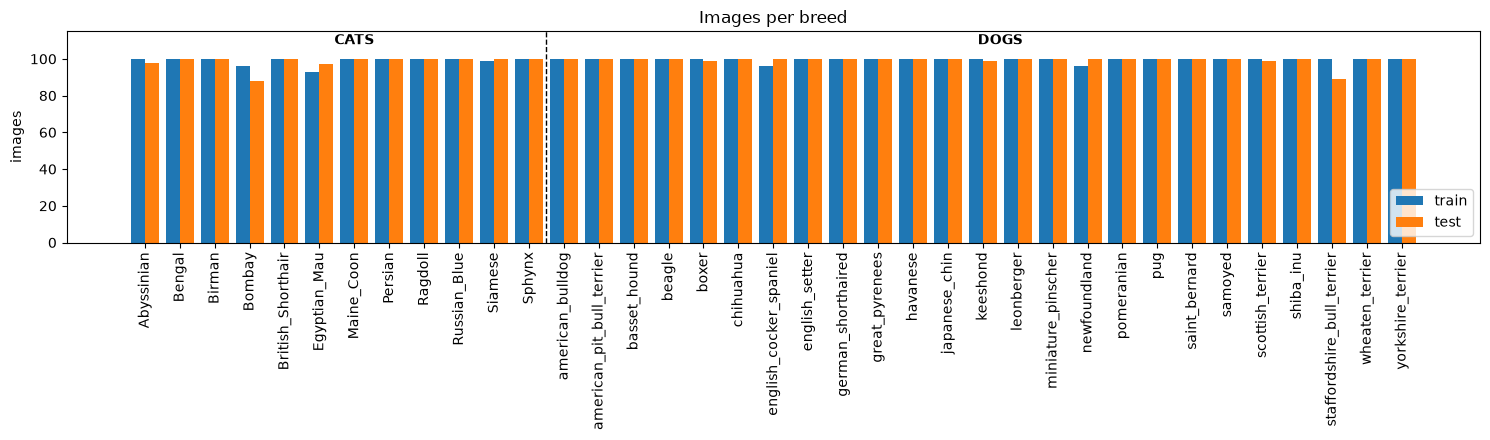

min/max images per class (train): 93 / 100


In [5]:
order = counts.reset_index()
x = np.arange(len(order))
fig, ax = plt.subplots(figsize=(15, 4.5))
ax.bar(x - 0.2, order["train"], 0.4, label="train")
ax.bar(x + 0.2, order["test"], 0.4, label="test")
n_cat = (order["species"] == "cat").sum()
ax.axvline(n_cat - 0.5, color="black", ls="--", lw=1)
ax.text(n_cat / 2, 108, "CATS", ha="center", weight="bold")
ax.text(n_cat + (len(order) - n_cat) / 2, 108, "DOGS", ha="center", weight="bold")
ax.set_xticks(x, order["label"], rotation=90)
ax.set_ylim(0, 115)
ax.set_ylabel("images")
ax.set_title("Images per breed")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

print("min/max images per class (train):", counts["train"].min(), "/", counts["train"].max())

ข้อมูล**เกือบสมดุล**: ชุดฝึกมี 93–100 ภาพต่อคลาส ชุดทดสอบมี 88–100 ภาพต่อคลาส จึงไม่จำเป็นต้องทำ oversampling หรือถ่วงน้ำหนักคลาส
แต่จำนวนสุนัข (25 สายพันธุ์) มากกว่าแมว (12 สายพันธุ์) ประมาณ 2 เท่า

### 3.2 ตัวอย่างภาพ (สายพันธุ์ละ 1 ภาพ จากชุดฝึก)

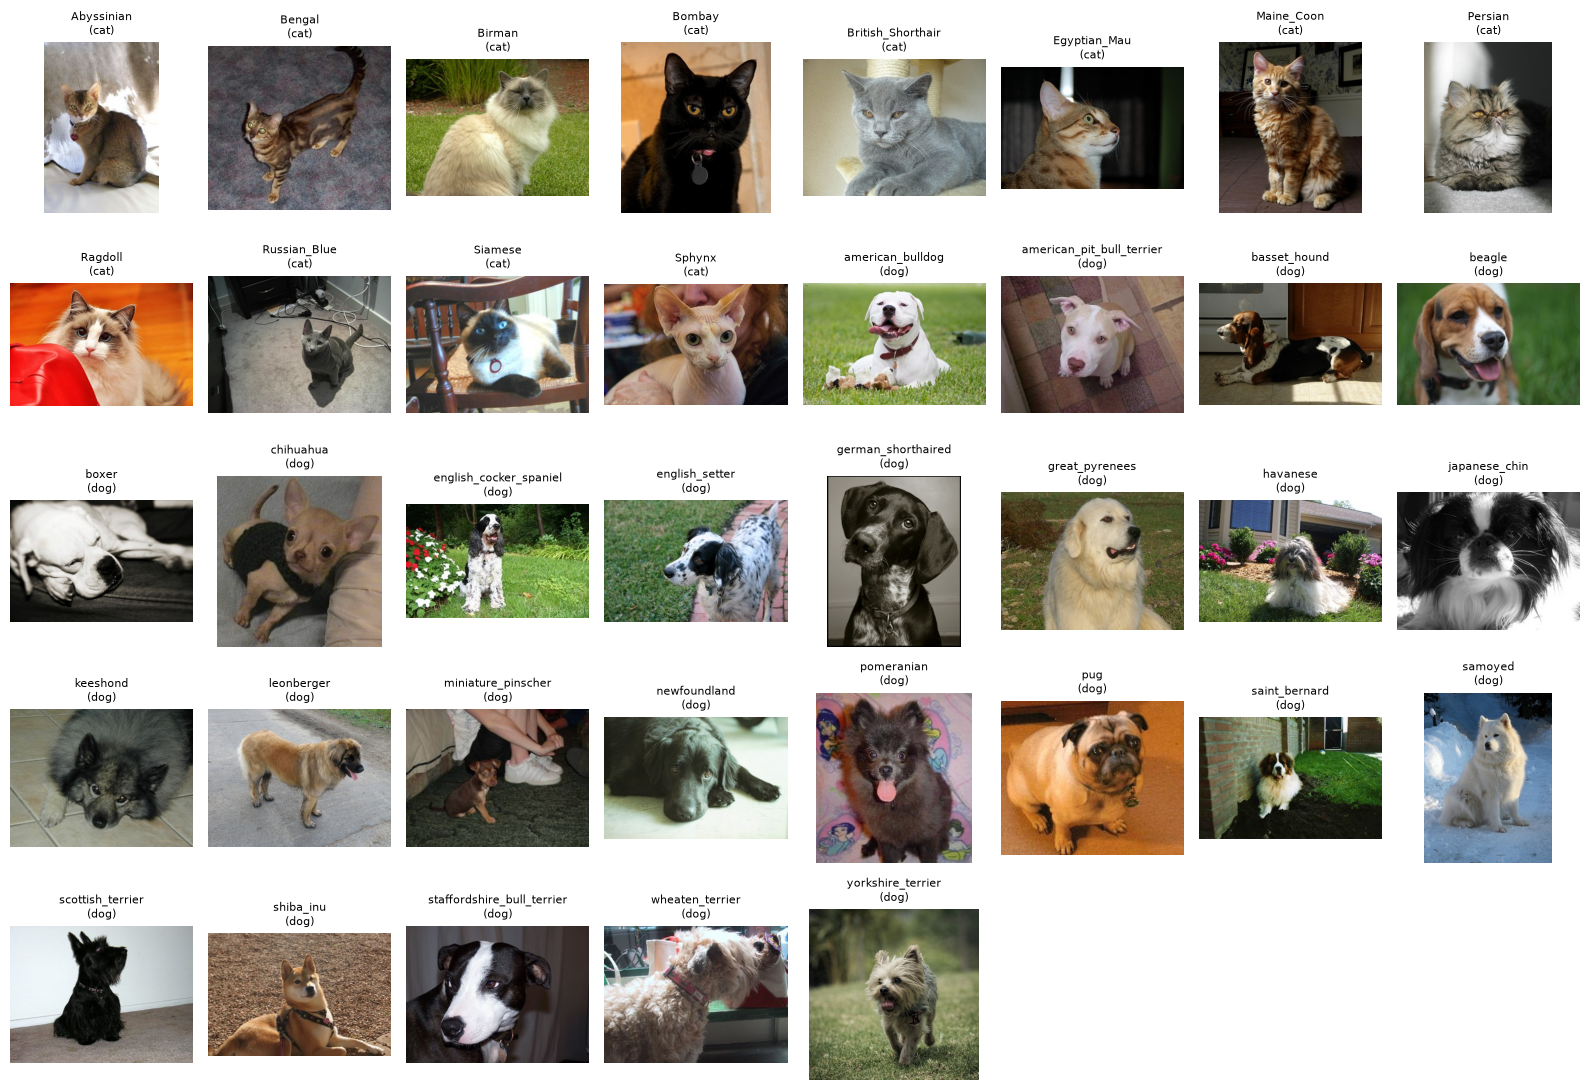

In [6]:
train_df = df[df["split"] == "train"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

samples = (train_df.groupby("label").sample(1, random_state=SEED)
                   .sort_values(["species", "label"], key=lambda s: s.str.lower()))
fig, axes = plt.subplots(5, 8, figsize=(16, 11))
for ax in axes.flat:
    ax.axis("off")
for ax, (_, r) in zip(axes.flat, samples.iterrows()):
    with Image.open(r["path"]) as img:
        ax.imshow(img)
    ax.set_title(f"{r['label']}\n({r['species']})", fontsize=8)
plt.tight_layout()
plt.show()

ภาพเป็นภาพถ่ายจริงที่หลากหลายมาก: มีทั้งภาพเต็มตัวและเฉพาะหน้า, มีคนหรือวัตถุอื่นอยู่ในภาพ, แสงและมุมกล้องต่างกัน
ซึ่งใกล้เคียงกับภาพที่ผู้ใช้จะอัปโหลดเข้าแอปจริง

### 3.3 ขนาดภาพ และตรวจภาพซ้ำระหว่างชุดฝึกกับชุดทดสอบ

,width,height,aspect_ratio
count,7349.00,7349.00,7349.00
mean,289.02,258.85,1.17
std,44.18,45.95,0.33
min,114.00,103.00,0.42
25%,240.00,214.00,0.75
50%,320.00,240.00,1.33
75%,320.00,320.00,1.50
max,320.00,320.00,2.56


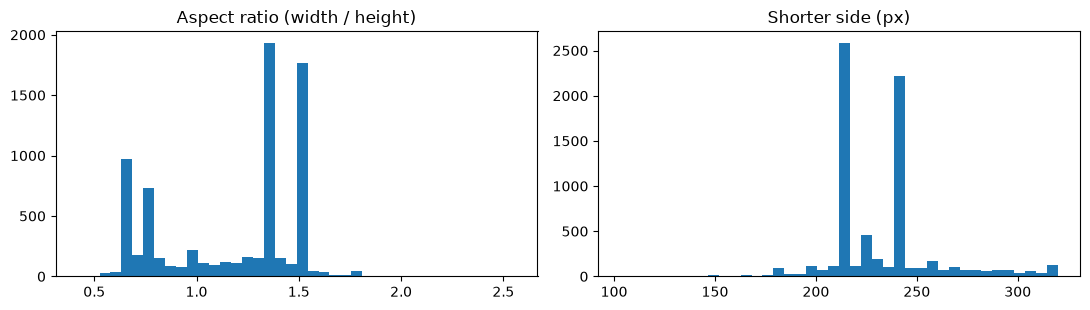

In [7]:
def image_size(path):
    with Image.open(path) as img:
        return img.size

sizes = pd.DataFrame([image_size(p) for p in df["path"]], columns=["width", "height"])
sizes["aspect_ratio"] = sizes["width"] / sizes["height"]
display(sizes.describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].hist(sizes["aspect_ratio"], bins=40)
axes[0].set_title("Aspect ratio (width / height)")
axes[1].hist(np.minimum(sizes["width"], sizes["height"]), bins=40)
axes[1].set_title("Shorter side (px)")
plt.tight_layout()
plt.show()

In [8]:
# Exact-duplicate check: identical files in both train and test would leak test information
df["md5"] = [hashlib.md5(p.read_bytes()).hexdigest() for p in df["path"]]
dup_groups = df[df.duplicated("md5", keep=False)].groupby("md5")
cross_split = [g for _, g in dup_groups if g["split"].nunique() > 1]
print(f"duplicate groups: {dup_groups.ngroups}, groups spanning train AND test: {len(cross_split)}")
if cross_split:
    display(pd.concat(cross_split)[["filepath", "label", "split"]])

duplicate groups: 0, groups spanning train AND test: 0


- ภาพทุกภาพถูกย่อให้ด้านยาวสุด 320 px แล้ว แต่สัดส่วนภาพต่างกัน (ส่วนใหญ่ 0.6–1.6) แบบจำลองจึงต้องรับภาพที่ย่อ/ครอปให้เป็นขนาดเดียวกัน (หัวข้อ 4)
- ผลตรวจภาพซ้ำแบบไฟล์ตรงกันทุกไบต์แสดงอยู่ด้านบน — ถ้าพบภาพซ้ำข้ามชุดจะทำให้ผลบนชุดทดสอบดีเกินจริง

## 4. การเตรียมภาพและสกัดคุณลักษณะ

ชุดฝึกมีเพียง ~100 ภาพต่อสายพันธุ์ ซึ่ง**น้อยเกินไปสำหรับการฝึก CNN ตั้งแต่ศูนย์** จึงใช้ **transfer learning แบบ feature extraction**:

1. **แปลงเป็น RGB** (กันภาพขาวดำ/มี alpha)
2. **ย่อขนาดแล้วครอปกลางภาพให้ได้ 224×224 px** และ **normalize ด้วยค่าเฉลี่ย/ส่วนเบี่ยงเบนมาตรฐานของ ImageNet** —
   ใช้ `weights.transforms()` ซึ่งเป็นขั้นตอนเตรียมภาพทางการของ weights แต่ละตัว
3. ส่งภาพเข้า **CNN ที่ฝึกบน ImageNet แล้ว** (ไม่ปรับ weights) โดยตัดชั้นจำแนกสุดท้ายออก
   ผลลัพธ์คือ**เวกเตอร์คุณลักษณะ** 1 เวกเตอร์ต่อภาพ (global average pooling ของ feature map ชั้นสุดท้าย)
4. ปรับสเกลเวกเตอร์ด้วย `StandardScaler` (ฟิตจากชุดฝึกเท่านั้น อยู่ใน Pipeline) แล้วจึงเข้าตัวจำแนก

ตัวสกัดคุณลักษณะ 2 แบบที่จะเปรียบเทียบ:

| Backbone | มิติของเวกเตอร์ | ขนาด weights | หมายเหตุ |
|---|---|---|---|
| EfficientNet-B0 | 1280 | ~20 MB | เล็กและเร็ว |
| ConvNeXt-Tiny | 768 | ~110 MB | ใหญ่กว่า สถาปัตยกรรมใหม่กว่า |

โค้ดทั้งหมดอยู่ใน `app/feature_extractor.py` ซึ่ง**แอป Gradio import ไปใช้ตัวเดียวกัน** ทำให้แอปเตรียมภาพเหมือนตอนฝึกทุกประการ

In [9]:
for name in BACKBONES:
    print(name, "->", FeatureExtractor(name).transform, "\n")

efficientnet_b0 -> ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BICUBIC
) 



convnext_tiny -> ImageClassification(
    crop_size=[224]
    resize_size=[236]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
) 



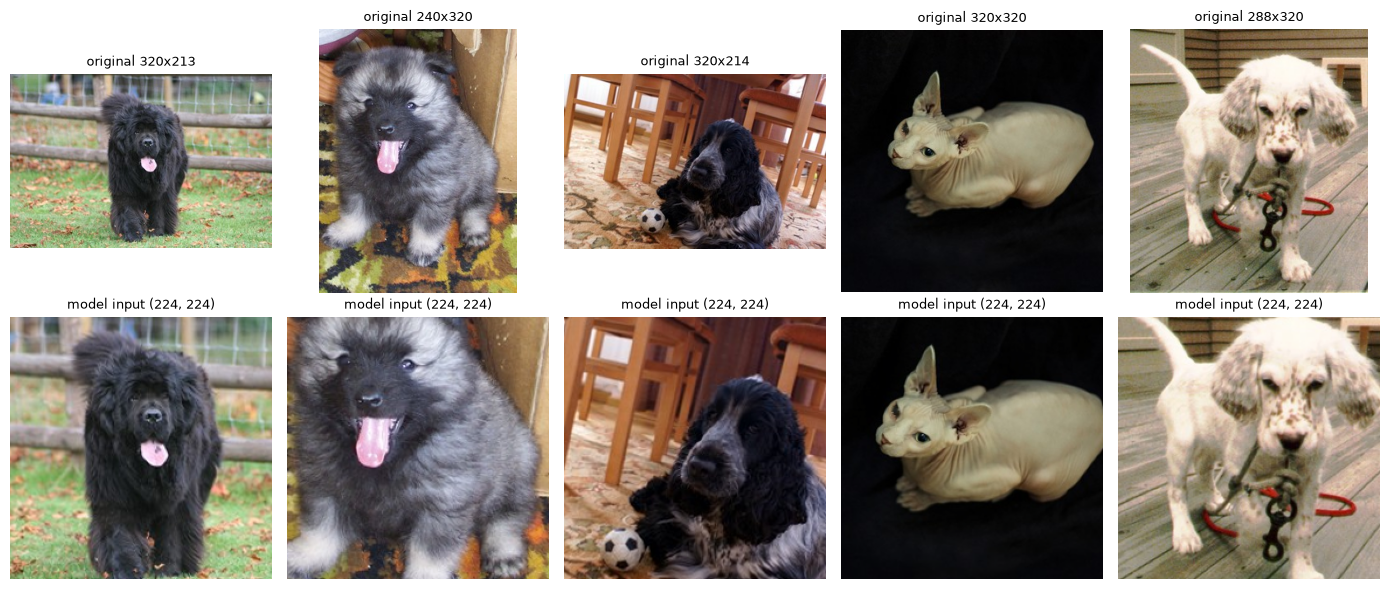

In [10]:
# Show what the model actually sees after preprocessing (EfficientNet-B0 transform)
fe_demo = FeatureExtractor("efficientnet_b0")
mean, std = np.array([0.485, 0.456, 0.406]), np.array([0.229, 0.224, 0.225])
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for i, (_, r) in enumerate(train_df.sample(5, random_state=SEED).iterrows()):
    with Image.open(r["path"]) as img:
        img = img.convert("RGB")
    tensor = fe_demo.transform(img)
    axes[0, i].imshow(img)
    axes[0, i].set_title(f"original {img.size[0]}x{img.size[1]}", fontsize=9)
    axes[1, i].imshow(np.clip(tensor.permute(1, 2, 0).numpy() * std + mean, 0, 1))
    axes[1, i].set_title(f"model input {tuple(tensor.shape[1:])}", fontsize=9)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. แบ่งข้อมูลสำหรับฝึกและทดสอบ

- ใช้ **split ทางการของชุดข้อมูล**: `train` = 3,680 ภาพ, `test` = 3,669 ภาพ (แต่ละคลาสถูกแบ่งประมาณครึ่งต่อครึ่ง) — ทำซ้ำได้เหมือนเดิมทุกครั้ง
- **ชุดทดสอบถูกกันไว้** ใช้ครั้งเดียวในหัวข้อ 7 หลังจากเลือกแบบจำลองเสร็จแล้ว
- การเลือก backbone, ตัวจำแนก และ hyperparameter ใช้ **Stratified 5-fold cross-validation บนชุดฝึกเท่านั้น**

In [11]:
y_train = train_df["label"].to_numpy()
y_test = test_df["label"].to_numpy()
print("train:", len(train_df), " test:", len(test_df))
print("overlap of files between train/test:", len(set(train_df["filepath"]) & set(test_df["filepath"])))

train: 3680  test: 3669
overlap of files between train/test: 0


In [12]:
def get_features(backbone, split_df, split):
    """Extract CNN features for every image in split_df (cached to FEAT_DIR as .npy)."""
    cache = FEAT_DIR / f"{backbone}_{split}.npy"
    if cache.exists():
        X = np.load(cache)
        if len(X) == len(split_df):
            print(f"[cache] {cache.name} {X.shape}")
            return X
    start = time.time()
    X = FeatureExtractor(backbone).extract_paths(list(split_df["path"]))
    np.save(cache, X)
    print(f"[extract] {backbone}/{split}: {X.shape} in {time.time() - start:.0f}s")
    return X

# Only TRAIN features are needed for model selection
X_train_all = {name: get_features(name, train_df, "train") for name in BACKBONES}

[cache] efficientnet_b0_train.npy (3680, 1280)
[cache] convnext_tiny_train.npy (3680, 768)


## 6. ฝึกและเลือกแบบจำลอง (ใช้ชุดฝึกเท่านั้น)

เปรียบเทียบตัวจำแนก 3 แบบบนคุณลักษณะจากทั้ง 2 backbone ด้วย 5-fold CV (scoring = macro-F1):

| ตัวจำแนก | เหตุผลที่ลอง |
|---|---|
| **Logistic Regression** (multinomial) | เส้นตรง เหมาะกับเวกเตอร์คุณลักษณะจาก CNN ที่แยกคลาสได้ดีอยู่แล้ว, ให้ความน่าจะเป็นที่ใช้แสดงในแอปได้โดยตรง, ไฟล์โมเดลเล็ก |
| **SVM (RBF kernel)** | จับขอบเขตที่ไม่เป็นเส้นตรงได้ |
| **k-Nearest Neighbors** | baseline ที่ไม่ต้องฝึก — ดูว่าคุณลักษณะจาก CNN จัดกลุ่มสายพันธุ์ได้ดีแค่ไหน |

ทุกตัวอยู่ใน Pipeline `StandardScaler → classifier` เพื่อให้การปรับสเกลฟิตเฉพาะข้อมูลฝึกในแต่ละ fold

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
pipe = Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression())])
param_grid = [
    {"clf": [LogisticRegression(max_iter=3000)], "clf__C": [0.01, 0.1, 1.0]},
    {"clf": [SVC(kernel="rbf", probability=True, random_state=SEED)], "clf__C": [1.0, 10.0]},
    {"clf": [KNeighborsClassifier(weights="distance")], "clf__n_neighbors": [5, 15]},
]

cv_tables = []
for name, X in X_train_all.items():
    start = time.time()
    gs = GridSearchCV(pipe, param_grid, cv=cv, scoring="f1_macro", n_jobs=-1, refit=False)
    gs.fit(X, y_train)
    res = pd.DataFrame(gs.cv_results_)
    res["backbone"] = name
    res["classifier"] = res["param_clf"].map(lambda m: type(m).__name__)
    res["hyperparams"] = res["params"].map(
        lambda p: ", ".join(f"{k.split('__')[1]}={v}" for k, v in p.items() if k != "clf"))
    cv_tables.append(res)
    print(f"{name}: grid search done in {time.time() - start:.0f}s")

cv_results = (pd.concat(cv_tables, ignore_index=True)
                .sort_values("mean_test_score", ascending=False)
                .reset_index(drop=True))
cv_results[["backbone", "classifier", "hyperparams", "mean_test_score", "std_test_score", "mean_fit_time"]] \
    .rename(columns={"mean_test_score": "cv_macro_f1", "std_test_score": "cv_std"}).round(4)

efficientnet_b0: grid search done in 177s


convnext_tiny: grid search done in 58s


,backbone,classifier,hyperparams,cv_macro_f1,cv_std,mean_fit_time
0,convnext_tiny,LogisticRegression,C=0.1,0.9541,0.0080,1.7658
1,convnext_tiny,LogisticRegression,C=0.01,0.9530,0.0090,3.0184
2,convnext_tiny,LogisticRegression,C=1.0,0.9517,0.0065,1.4829
3,convnext_tiny,SVC,C=10.0,0.9514,0.0077,51.3510
4,convnext_tiny,SVC,C=1.0,0.9504,0.0060,50.6918
5,efficientnet_b0,LogisticRegression,C=0.01,0.9377,0.0089,7.7334
6,efficientnet_b0,LogisticRegression,C=0.1,0.9360,0.0080,5.2521
7,efficientnet_b0,LogisticRegression,C=1.0,0.9345,0.0102,4.7665
8,efficientnet_b0,SVC,C=10.0,0.9339,0.0124,128.5714
9,efficientnet_b0,SVC,C=1.0,0.9241,0.0101,126.7789


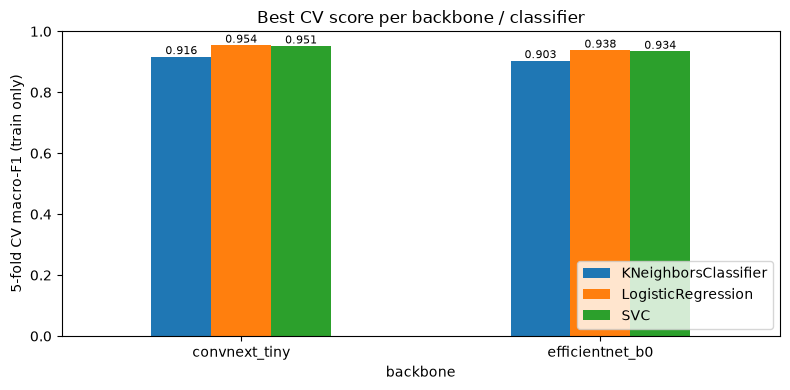

In [14]:
best_per = (cv_results.groupby(["backbone", "classifier"])["mean_test_score"].max()
                      .unstack("classifier"))
ax = best_per.plot.bar(figsize=(8, 4), rot=0)
ax.set_ylabel("5-fold CV macro-F1 (train only)")
ax.set_ylim(0, 1)
ax.set_title("Best CV score per backbone / classifier")
ax.legend(loc="lower right")
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=8)
plt.tight_layout()
plt.show()

In [15]:
best = cv_results.iloc[0]
BACKBONE = best["backbone"]
final_model = clone(pipe).set_params(**best["params"])
print(f"Selected: {BACKBONE} + {best['classifier']} ({best['hyperparams']})")
print(f"CV macro-F1 = {best['mean_test_score']:.4f} ± {best['std_test_score']:.4f}")

# Refit the selected pipeline on the FULL training set
start = time.time()
final_model.fit(X_train_all[BACKBONE], y_train)
print(f"final model trained on {len(y_train)} images in {time.time() - start:.1f}s")
print(final_model)

Selected: convnext_tiny + LogisticRegression (C=0.1)
CV macro-F1 = 0.9541 ± 0.0080


final model trained on 3680 images in 0.5s
Pipeline(steps=[('scaler', StandardScaler()),
                ('clf', LogisticRegression(C=0.1, max_iter=3000))])


**ผลการเลือกแบบจำลอง (5-fold CV บนชุดฝึก):**
- **ConvNeXt-Tiny ให้คุณลักษณะที่ดีกว่า EfficientNet-B0 ทุกตัวจำแนก** (Logistic Regression ดีที่สุด 0.954 เทียบกับ 0.938)
  แม้เวกเตอร์จะสั้นกว่า (768 vs 1280 มิติ) แต่ใช้เวลาสกัดคุณลักษณะนานกว่าประมาณ 4–5 เท่า ซึ่งสำหรับแอปที่ทำนายทีละภาพยังเร็วพอ (~0.1–0.2 วินาที/ภาพบน CPU)
- **Logistic Regression ดีที่สุด** และ SVM (RBF) ใกล้เคียงกันมาก (0.951) แต่ SVM ใช้เวลาฝึกนานกว่า ~17 เท่าและไฟล์โมเดลใหญ่กว่า
  เพราะต้องเก็บ support vectors — แสดงว่าคุณลักษณะจาก CNN **แยกคลาสได้ด้วยเส้นตรงอยู่แล้ว** ตัวจำแนกที่ซับซ้อนขึ้นจึงไม่ได้ช่วย
- kNN ได้ต่ำสุด (0.916) แต่ก็ยังสูง แสดงว่าภาพสายพันธุ์เดียวกันอยู่ใกล้กันในปริภูมิคุณลักษณะ
- ค่า C = 0.1 (regularization ปานกลาง) ดีที่สุด และค่า std ระหว่าง fold ต่ำ (~0.008) แสดงว่าผลค่อนข้างเสถียร

**แบบจำลองที่เลือก:** ConvNeXt-Tiny (frozen) → StandardScaler → Logistic Regression (C = 0.1) แล้วฝึกใหม่ด้วยชุดฝึกทั้งหมด 3,680 ภาพ

## 7. ประเมินผลบนชุดทดสอบ

ชุดทดสอบถูกใช้ที่นี่เป็นครั้งแรก — สกัดคุณลักษณะด้วย backbone ที่เลือกไว้ แล้ววัดผลแบบจำลองสุดท้าย

In [16]:
X_test = get_features(BACKBONE, test_df, "test")
y_pred = final_model.predict(X_test)
proba = final_model.predict_proba(X_test)
classes = final_model.classes_

p_macro, r_macro, f1_macro, _ = precision_recall_fscore_support(y_test, y_pred, average="macro")
test_metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "macro_precision": p_macro,
    "macro_recall": r_macro,
    "macro_f1": f1_macro,
    "weighted_f1": f1_score(y_test, y_pred, average="weighted"),
    "top3_accuracy": top_k_accuracy_score(y_test, proba, k=3, labels=classes),
    "top5_accuracy": top_k_accuracy_score(y_test, proba, k=5, labels=classes),
}
pd.Series(test_metrics, name="test set").round(4).to_frame()

[cache] convnext_tiny_test.npy (3669, 768)


,test set
accuracy,0.9338
macro_precision,0.9346
macro_recall,0.9334
macro_f1,0.9335
weighted_f1,0.9338
top3_accuracy,0.9926
top5_accuracy,0.9973


**แปลความหมายผลบนชุดทดสอบ (3,669 ภาพที่ไม่เคยใช้ในการฝึกหรือเลือกแบบจำลอง):**
- **Macro-F1 = 0.934 (เมตริกหลัก)** — เมื่อเฉลี่ยทุกสายพันธุ์อย่างเท่ากัน แบบจำลองทั้งแม่น (precision) และครอบคลุม (recall) ราว 93%
- **Accuracy = 93.4%** — จาก 100 ภาพ ทายสายพันธุ์ถูกประมาณ 93 ภาพ (จาก 37 ตัวเลือก ถ้าเดาสุ่มจะถูกเพียง ~2.7%)
- **Top-3 accuracy = 99.3%** — คำตอบที่ถูกอยู่ใน 3 อันดับแรกเกือบทุกภาพ จึงเหมาะที่แอปจะแสดง 3 อันดับ
- Macro-F1 กับ weighted-F1 แทบเท่ากัน เพราะทุกคลาสมีจำนวนภาพใกล้เคียงกัน
- ผลบนชุดทดสอบต่ำกว่า CV (0.954) ประมาณ 2 จุด ซึ่งเป็นเรื่องปกติ เพราะค่า CV ถูกใช้เลือกแบบจำลองจึงมองโลกในแง่ดีเล็กน้อย
  และชุดฝึกมีเพียง ~100 ภาพ/คลาส — ส่วนต่างที่น้อยแสดงว่าแบบจำลอง **ไม่ overfit มาก**

### 7.1 ผลรายคลาส (precision / recall / F1 ของแต่ละสายพันธุ์)
ค่าเฉลี่ยในตาราง: **macro avg** = เฉลี่ยทุกคลาสเท่ากัน (เมตริกหลัก), **weighted avg** = ถ่วงน้ำหนักด้วยจำนวนภาพของคลาส

In [17]:
report = pd.DataFrame(classification_report(y_test, y_pred, output_dict=True, zero_division=0)).T
per_class = report.loc[classes].copy()
per_class.insert(0, "species", per_class.index.map(species_of))
per_class["support"] = per_class["support"].astype(int)
display(report.loc[["macro avg", "weighted avg"]].round(4))
display(per_class.groupby("species")["f1-score"].agg(["mean", "min", "max"]).round(3).rename_axis("F1 by species"))
per_class.sort_values("f1-score", ascending=False).round(3)

,precision,recall,f1-score,support
macro avg,0.9346,0.9334,0.9335,3669.0
weighted avg,0.9350,0.9338,0.9338,3669.0


,mean,min,max
F1 by species,,,
cat,0.886,0.745,0.972
dog,0.956,0.736,1.000


,species,precision,recall,f1-score,support
leonberger,dog,1.000,1.000,1.000,100
newfoundland,dog,0.990,1.000,0.995,100
yorkshire_terrier,dog,0.990,1.000,0.995,100
scottish_terrier,dog,0.990,1.000,0.995,99
pomeranian,dog,0.980,1.000,0.990,100
japanese_chin,dog,0.980,1.000,0.990,100
saint_bernard,dog,0.990,0.990,0.990,100
english_setter,dog,0.990,0.990,0.990,100
great_pyrenees,dog,0.990,0.990,0.990,100
pug,dog,1.000,0.980,0.990,100


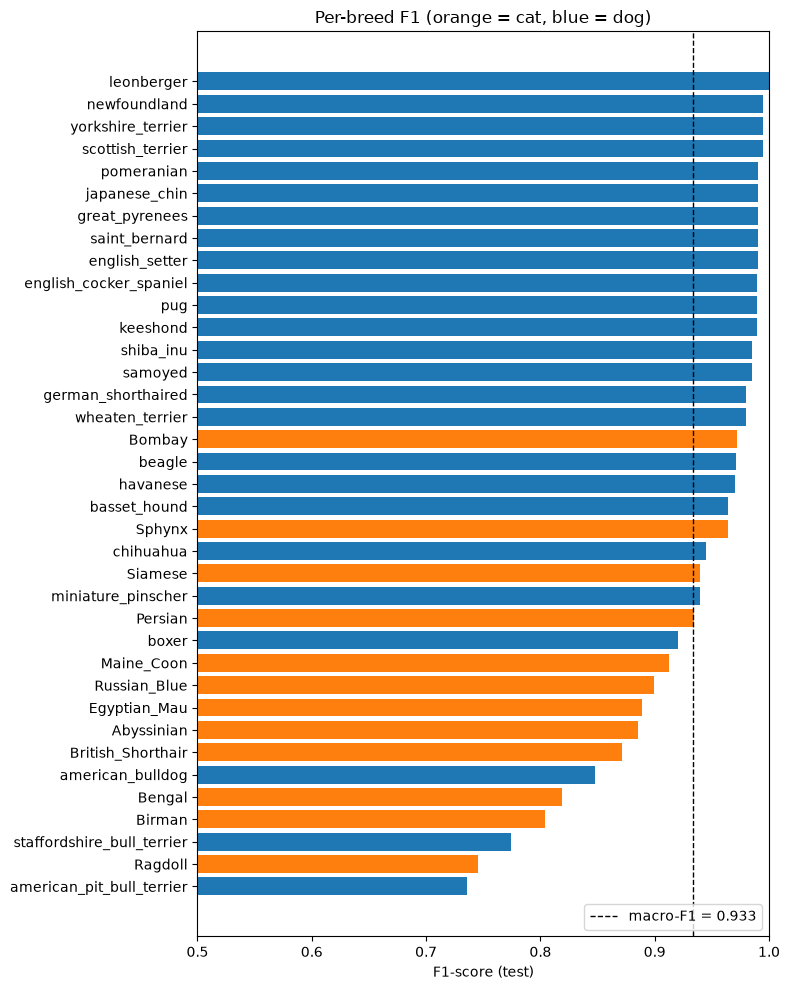

In [18]:
pc = per_class.sort_values("f1-score")
colors = pc["species"].map({"cat": "tab:orange", "dog": "tab:blue"})
fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(pc.index, pc["f1-score"], color=colors)
ax.axvline(f1_macro, color="black", ls="--", lw=1, label=f"macro-F1 = {f1_macro:.3f}")
ax.set_xlim(0.5, 1.0)
ax.set_xlabel("F1-score (test)")
ax.set_title("Per-breed F1 (orange = cat, blue = dog)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 7.2 Confusion matrix
แต่ละแถวคือสายพันธุ์จริง normalize ให้ผลรวมแถวเป็น 1 (ค่าในแนวทแยง = recall ของคลาสนั้น) เส้นแดงแบ่งแมว (บนซ้าย) กับสุนัข (ล่างขวา)

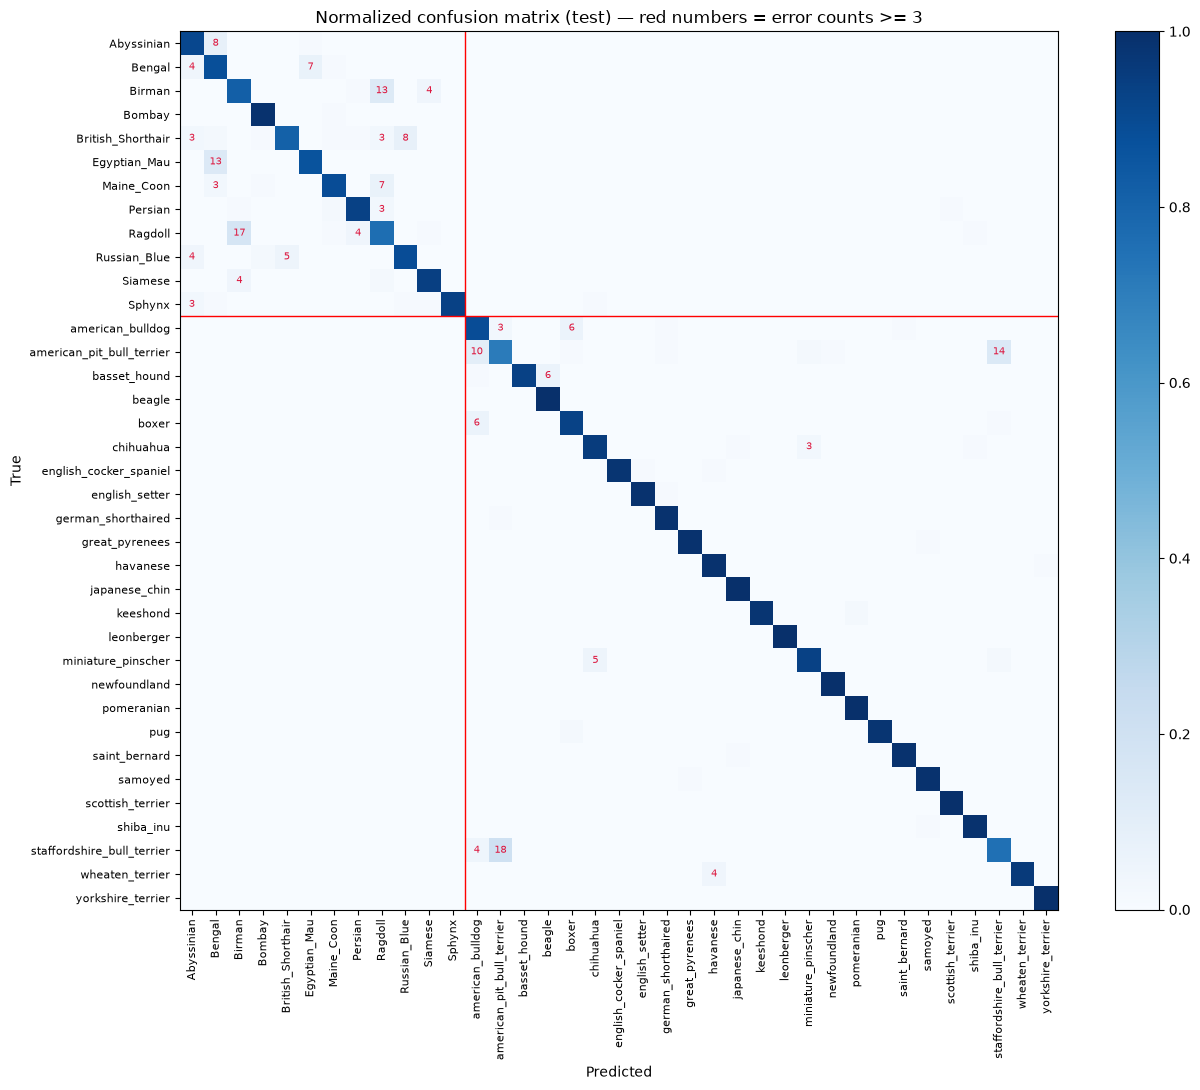

In [19]:
order_labels = sorted(classes, key=lambda c: (species_of[c], c.lower()))
cm = confusion_matrix(y_test, y_pred, labels=order_labels)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(13, 11))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(order_labels)), order_labels, rotation=90, fontsize=8)
ax.set_yticks(range(len(order_labels)), order_labels, fontsize=8)
n_cat = sum(species_of[c] == "cat" for c in order_labels)
ax.axhline(n_cat - 0.5, color="red", lw=1)
ax.axvline(n_cat - 0.5, color="red", lw=1)
for i in range(len(order_labels)):
    for j in range(len(order_labels)):
        if i != j and cm[i, j] >= 3:   # annotate notable off-diagonal errors
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="crimson")
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("Normalized confusion matrix (test) — red numbers = error counts >= 3")
fig.colorbar(im, fraction=0.04)
plt.tight_layout()
plt.show()

In [20]:
pairs = pd.DataFrame(cm, index=order_labels, columns=order_labels).stack().reset_index()
pairs.columns = ["true", "predicted", "count"]
pairs = pairs[(pairs["true"] != pairs["predicted"]) & (pairs["count"] > 0)]
pairs["% of true class"] = (100 * pairs["count"] / pairs["true"].map(pd.Series(y_test).value_counts())).round(1)
print("Most frequent confusions:")
pairs.sort_values("count", ascending=False).head(10).reset_index(drop=True)

Most frequent confusions:


,true,predicted,count,% of true class
0,staffordshire_bull_terrier,american_pit_bull_terrier,18,20.2
1,Ragdoll,Birman,17,17.0
2,american_pit_bull_terrier,staffordshire_bull_terrier,14,14.0
3,Birman,Ragdoll,13,13.0
4,Egyptian_Mau,Bengal,13,13.4
5,american_pit_bull_terrier,american_bulldog,10,10.0
6,British_Shorthair,Russian_Blue,8,8.0
7,Abyssinian,Bengal,8,8.2
8,Maine_Coon,Ragdoll,7,7.0
9,Bengal,Egyptian_Mau,7,7.0


In [21]:
true_sp = pd.Series(y_test).map(species_of)
pred_sp = pd.Series(y_pred).map(species_of)
n_err = (y_test != y_pred).sum()
n_cross = (true_sp != pred_sp).sum()
print(f"cat-vs-dog accuracy: {(true_sp == pred_sp).mean():.4f}")
print(f"total errors: {n_err}, errors that confuse a cat with a dog (or vice versa): {n_cross}")

cat-vs-dog accuracy: 0.9992
total errors: 243, errors that confuse a cat with a dog (or vice versa): 3


**ประเภทที่จำแนกได้ดี vs ประเภทที่ยังสับสน**
- **จำแนกได้ดีมาก (F1 ≥ 0.98):** ส่วนใหญ่เป็นสุนัขที่มีลักษณะเด่นเฉพาะตัว เช่น leonberger (F1 = 1.00), newfoundland, yorkshire_terrier, scottish_terrier, pomeranian, pug, samoyed
  และแมว Bombay (ดำล้วน) / Sphynx (ไม่มีขน) ก็ได้ ≥ 0.96
- **โดยรวมแมวยากกว่าสุนัข** (F1 เฉลี่ยแมว ~0.89 vs สุนัข ~0.96) — แมวหลายสายพันธุ์ต่างกันแค่ลายขน/สีขน ขณะที่สุนัขต่างกันทั้งรูปร่าง ขนาด และหน้าตา
  อีกเหตุผลหนึ่งคือ ImageNet ที่ใช้ฝึก backbone มีคลาสสุนัขกว่า 100 สายพันธุ์ แต่มีแมวเพียงไม่กี่คลาส คุณลักษณะที่ได้จึงแยกสุนัขได้ละเอียดกว่า
- **คู่ที่สับสนมากที่สุดเป็นสายพันธุ์ที่หน้าตาใกล้เคียงกันจริง:**
  - *staffordshire_bull_terrier ↔ american_pit_bull_terrier* (18 + 14 ภาพ) — รูปร่าง หัว และสีขนแทบเหมือนกัน แม้แต่คนก็แยกยาก จึงเป็น 2 คลาสที่ F1 ต่ำสุด
  - *Ragdoll ↔ Birman* (17 + 13 ภาพ) — แมวขนยาวสีแต้ม (colorpoint) ตาสีฟ้าเหมือนกัน ต่างกันที่ Birman มี "ถุงเท้าขาว" ซึ่งมักมองไม่เห็นในภาพ
  - *Egyptian_Mau → Bengal* (13), *Abyssinian → Bengal* (8) — แมวลายจุด/ลาย tabby สีน้ำตาลคล้ายกัน
  - *British_Shorthair → Russian_Blue* (8) — แมวขนสีเทาฟ้าทั้งคู่
  - *american_pit_bull_terrier → american_bulldog* (10) — สุนัขกลุ่ม bully รูปร่างใกล้กัน
- **แทบไม่สับสนระหว่างแมวกับสุนัข:** มีเพียง 3 จาก 243 ข้อผิดพลาด (แยกแมว/สุนัขถูก 99.9%) — ข้อผิดพลาดเกือบทั้งหมดเกิด **ภายใน** สายพันธุ์ที่ใกล้กัน

## 8. ตัวอย่างผลทำนายและวิเคราะห์ข้อผิดพลาด
### 8.1 ตัวอย่างผลทำนายแบบสุ่มจากชุดทดสอบ (เขียว = ถูก, แดง = ผิด)

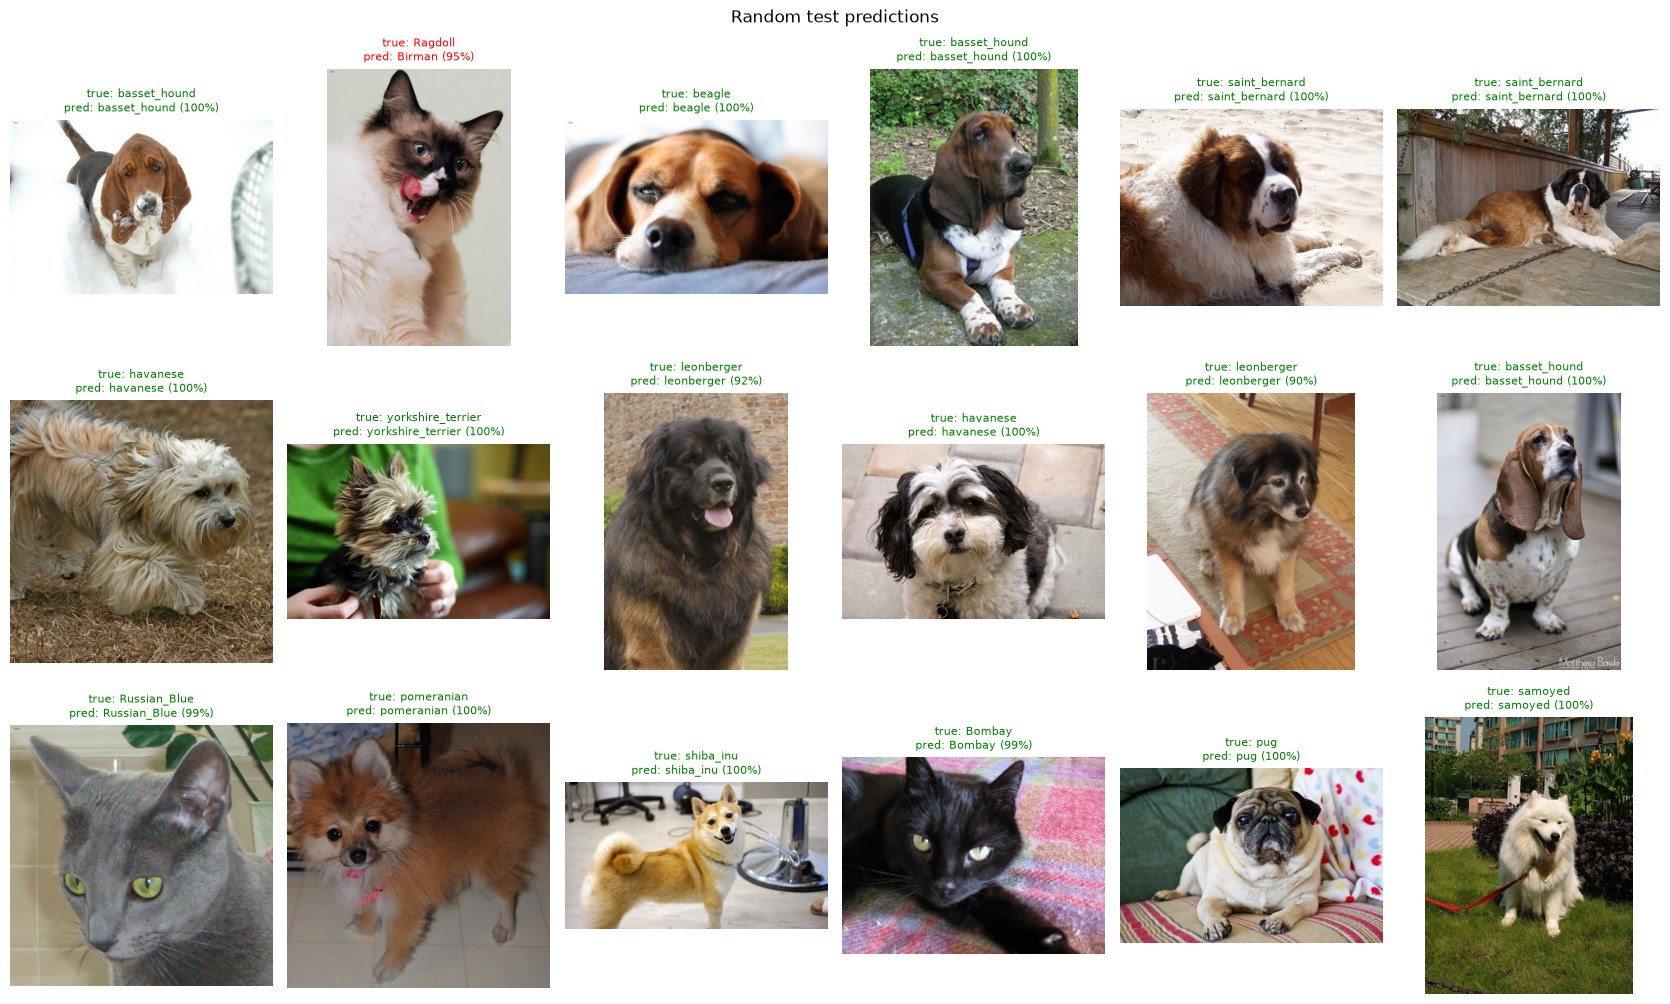

In [22]:
def show_predictions(indices, title):
    cols = 6
    rows = int(np.ceil(len(indices) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.8, rows * 3.4))
    for ax in axes.flat:
        ax.axis("off")
    for ax, i in zip(axes.flat, indices):
        ok = y_pred[i] == y_test[i]
        with Image.open(test_df.loc[i, "path"]) as img:
            ax.imshow(img)
        ax.set_title(f"true: {y_test[i]}\npred: {y_pred[i]} ({proba[i].max():.0%})",
                     fontsize=8, color="green" if ok else "red")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

rng = np.random.default_rng(SEED)
show_predictions(rng.choice(len(test_df), 18, replace=False), "Random test predictions")

### 8.2 ข้อผิดพลาดที่แบบจำลองมั่นใจมากที่สุด

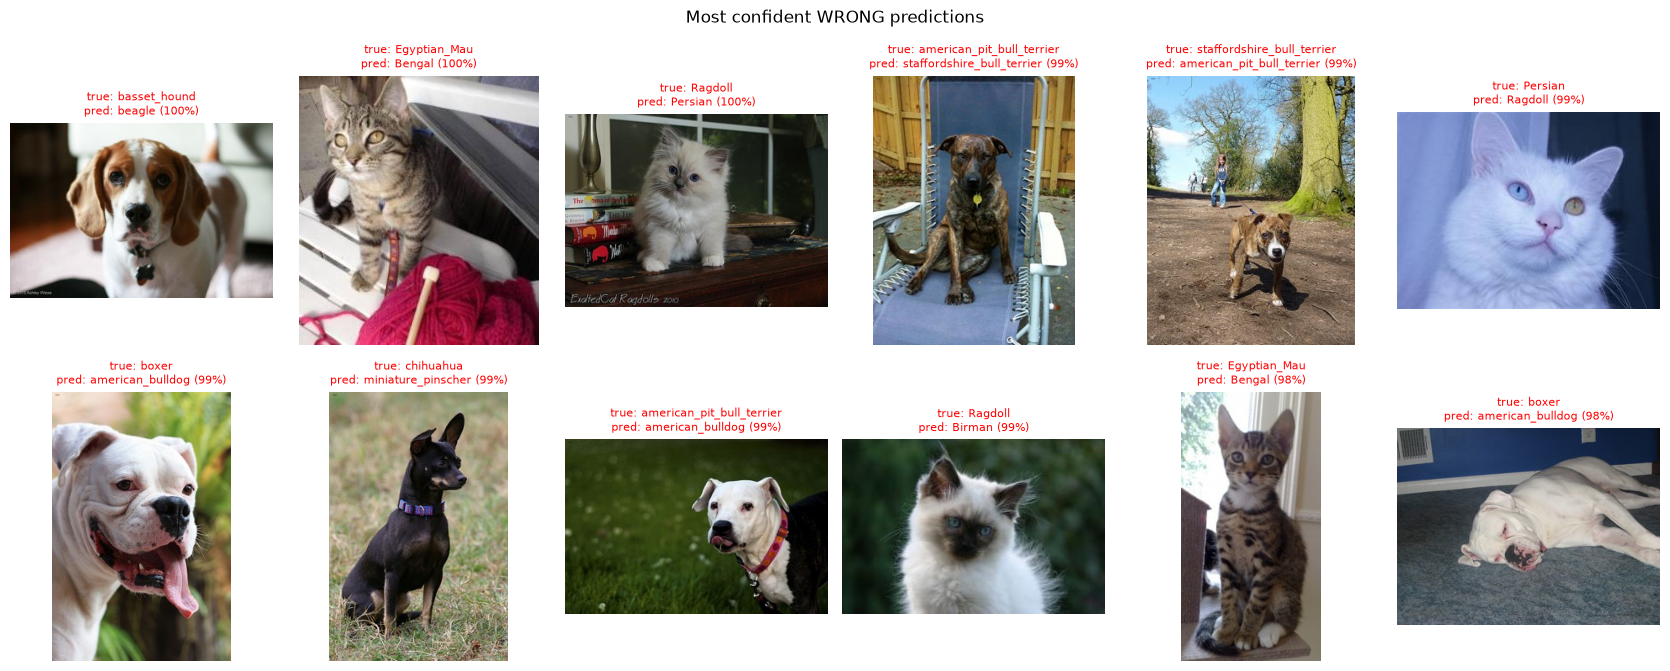

,image,true,top-3 predictions
0,test/basset_hound/basset_hound_200.jpg,basset_hound,"beagle 100%, basset_hound 0%, saint_bernard 0%"
1,test/Egyptian_Mau/Egyptian_Mau_215.jpg,Egyptian_Mau,"Bengal 100%, Egyptian_Mau 0%, Abyssinian 0%"
2,test/Ragdoll/Ragdoll_45.jpg,Ragdoll,"Persian 100%, Ragdoll 0%, Birman 0%"
3,test/american_pit_bull_terrier/american_pit_bu...,american_pit_bull_terrier,"staffordshire_bull_terrier 99%, american_pit_b..."
4,test/staffordshire_bull_terrier/staffordshire_...,staffordshire_bull_terrier,"american_pit_bull_terrier 99%, staffordshire_b..."
5,test/Persian/Persian_221.jpg,Persian,"Ragdoll 99%, Maine_Coon 0%, British_Shorthair 0%"
6,test/boxer/boxer_59.jpg,boxer,"american_bulldog 99%, boxer 1%, British_Shorth..."
7,test/chihuahua/chihuahua_85.jpg,chihuahua,"miniature_pinscher 99%, chihuahua 1%, german_s..."
8,test/american_pit_bull_terrier/american_pit_bu...,american_pit_bull_terrier,"american_bulldog 99%, american_pit_bull_terrie..."
9,test/Ragdoll/Ragdoll_252.jpg,Ragdoll,"Birman 99%, Ragdoll 1%, Siamese 0%"


In [23]:
conf = proba.max(axis=1)
correct = y_pred == y_test
wrong_idx = np.where(~correct)[0]
worst = wrong_idx[np.argsort(-conf[wrong_idx])][:12]
show_predictions(worst, "Most confident WRONG predictions")

def top3(i):
    idx = np.argsort(-proba[i])[:3]
    return ", ".join(f"{classes[k]} {proba[i][k]:.0%}" for k in idx)

pd.DataFrame({"image": test_df.loc[worst, "filepath"].values,
              "true": y_test[worst],
              "top-3 predictions": [top3(i) for i in worst]})

### 8.3 ความมั่นใจของแบบจำลอง: ทำนายถูก vs ทำนายผิด

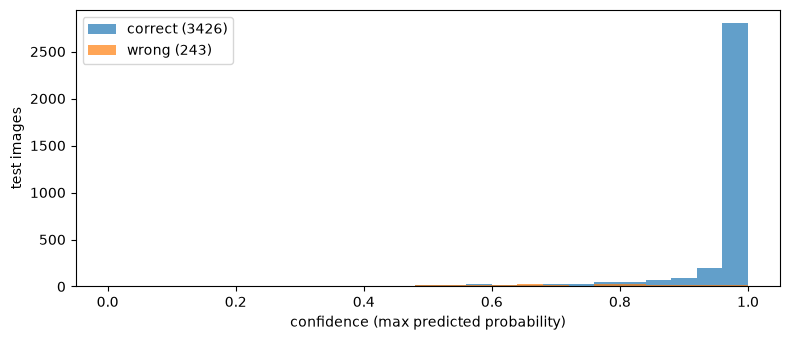

,confidence >=,coverage (% of images),accuracy on those
0,0.0,100.0,93.4
1,0.3,99.9,93.4
2,0.5,98.3,94.2
3,0.7,93.3,96.1
4,0.9,84.2,98.6


In [24]:
fig, ax = plt.subplots(figsize=(8, 3.5))
bins = np.linspace(0, 1, 26)
ax.hist(conf[correct], bins=bins, alpha=0.7, label=f"correct ({correct.sum()})")
ax.hist(conf[~correct], bins=bins, alpha=0.7, label=f"wrong ({(~correct).sum()})")
ax.set_xlabel("confidence (max predicted probability)")
ax.set_ylabel("test images")
ax.legend()
plt.tight_layout()
plt.show()

rows = []
for t in [0.0, 0.3, 0.5, 0.7, 0.9]:
    keep = conf >= t
    rows.append({"confidence >=": t, "coverage (% of images)": 100 * keep.mean(),
                 "accuracy on those": 100 * correct[keep].mean()})
pd.DataFrame(rows).round(1)

**วิเคราะห์ข้อผิดพลาด**
1. **สายพันธุ์ที่คล้ายกันมาก** (pit bull/staffordshire, Ragdoll/Birman, Egyptian Mau/Bengal) เป็นสาเหตุหลัก — ข้อผิดพลาดส่วนใหญ่ไปตกที่สายพันธุ์ที่ใกล้เคียงที่สุด
   และคำตอบที่ถูกมักอยู่ในอันดับ 2–3 (top-3 accuracy 99.3%)
2. **Label อาจผิดในชุดข้อมูลเอง:** เช่น `basset_hound_200` ในภาพดูเป็น beagle มากกว่า basset hound (ขาไม่สั้นและหูไม่ยาวแบบ basset) — แบบจำลองตอบ beagle 100%
3. **ภาพลูกแมว/ลูกสุนัข:** เช่น ลูกแมว Ragdoll ถูกทายเป็น Persian/Birman เพราะลักษณะเด่นของสายพันธุ์ยังไม่ชัดในวัยเด็ก
4. **มุมกล้อง/ท่าทาง/แสง:** ภาพสุนัขนอนหรือหันข้าง (เช่น boxer สีขาวนอนอยู่) ทำให้เห็นลักษณะเด่นไม่ครบ
5. **แบบจำลองมั่นใจเกินไปในบางภาพที่ผิด** (ความมั่นใจ 98–100%) จึงไม่ควรเชื่อค่าความน่าจะเป็นเป็นค่าสัมบูรณ์

**ความมั่นใจยังมีประโยชน์:** ภาพที่ความมั่นใจ ≥ 0.9 (84% ของภาพ) ทายถูก 98.6% แต่ถ้าความมั่นใจ < 0.5 ความแม่นยำลดลงมาก
→ ในแอปจะแสดง **3 อันดับแรกพร้อมความน่าจะเป็น** และแจ้งเตือนเมื่อความมั่นใจต่ำ (< 50%) ว่าผลอาจไม่ถูกต้อง

## 9. บันทึกแบบจำลองสำหรับเว็บแอป

บันทึกเป็น `app/model.joblib` ประกอบด้วย:
- `model` — Pipeline (`StandardScaler` + ตัวจำแนก) ที่ฝึกแล้ว
- `backbone` — ชื่อ CNN ที่ใช้สกัดคุณลักษณะ (แอปสร้าง `FeatureExtractor(backbone)` จาก `feature_extractor.py` ตัวเดียวกัน)
- `classes`, `species` — ชื่อคลาสและชนิดสัตว์ของแต่ละคลาส
- `test_metrics` — ผลประเมินบนชุดทดสอบ

และคัดลอกภาพตัวอย่างจากชุดทดสอบไว้ที่ `app/examples/` สำหรับให้ผู้ใช้กดทดลองในแอป

In [25]:
bundle = {
    "model": final_model,
    "backbone": BACKBONE,
    "classes": list(classes),
    "species": {c: species_of[c] for c in classes},
    "test_metrics": {k: round(float(v), 4) for k, v in test_metrics.items()},
    "sklearn_version": sklearn.__version__,
}
model_path = APP_DIR / "model.joblib"
joblib.dump(bundle, model_path, compress=3)
print(f"saved {model_path.relative_to(PROJECT_DIR)} ({model_path.stat().st_size / 1e6:.2f} MB)")

# Example images for the app (one per chosen breed, from the TEST set)
EXAMPLE_BREEDS = ["Persian", "Siamese", "Bengal", "pug", "samoyed", "beagle", "shiba_inu", "american_pit_bull_terrier"]
ex_dir = APP_DIR / "examples"
ex_dir.mkdir(exist_ok=True)
example_rows = {}                                   # example file -> row in test_df
for breed in EXAMPLE_BREEDS:
    row = test_df.index[(test_df["label"] == breed) & (y_pred == breed)][0]   # a correctly classified image
    shutil.copy(test_df.loc[row, "path"], ex_dir / f"{breed}.jpg")
    example_rows[f"{breed}.jpg"] = row
print("examples:", sorted(p.name for p in ex_dir.glob("*.jpg")))

saved app\model.joblib (0.13 MB)
examples: ['Bengal.jpg', 'Persian.jpg', 'Siamese.jpg', 'american_pit_bull_terrier.jpg', 'beagle.jpg', 'pug.jpg', 'samoyed.jpg', 'shiba_inu.jpg']


### 9.1 ทดสอบโหลดแบบจำลองกลับมาใช้แบบเดียวกับแอป
โหลด `model.joblib` ใหม่ → สกัดคุณลักษณะจากไฟล์ภาพด้วย `FeatureExtractor` → ทำนาย และตรวจว่าคุณลักษณะตรงกับที่ใช้ประเมินผล

features match the evaluation features ✔


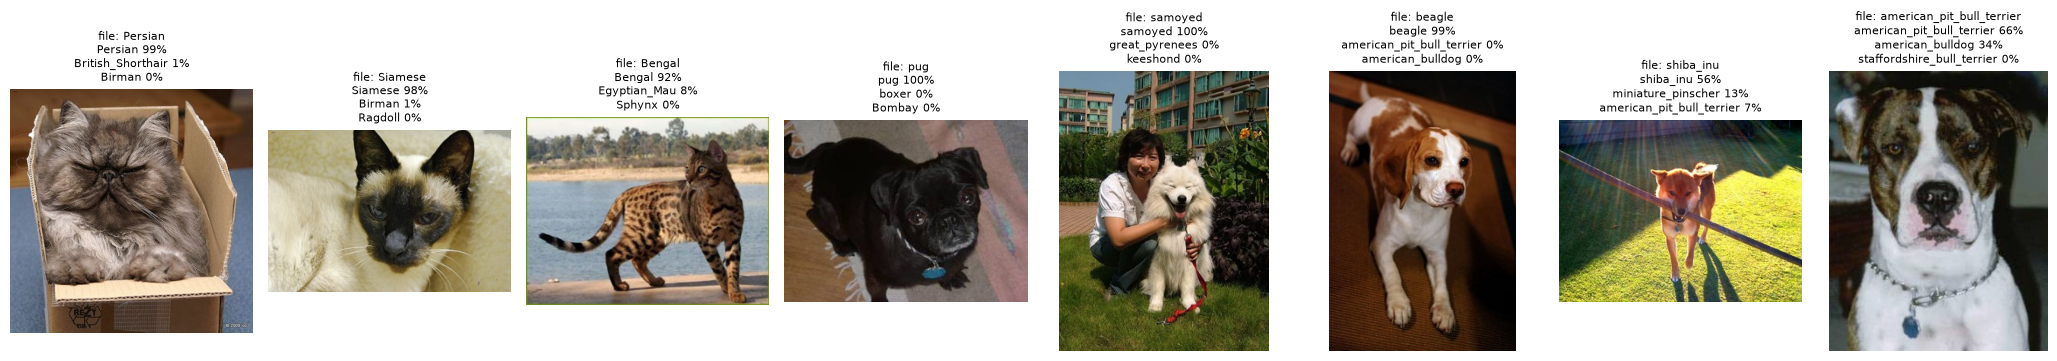

In [26]:
loaded = joblib.load(model_path)
fe = FeatureExtractor(loaded["backbone"])

ex_paths = [ex_dir / name for name in example_rows]
images = [Image.open(p) for p in ex_paths]
feats = fe.extract(images)
probs = loaded["model"].predict_proba(feats)

# Same image -> same features as in the evaluation above (preprocessing is identical)
for p, f in zip(ex_paths, feats):
    assert np.allclose(f, X_test[example_rows[p.name]], atol=1e-4), p.name
print("features match the evaluation features ✔")

fig, axes = plt.subplots(1, len(images), figsize=(2.6 * len(images), 3.6))
for ax, img, p, pr in zip(axes, images, ex_paths, probs):
    k = np.argsort(-pr)[:3]
    ax.imshow(img)
    ax.axis("off")
    ax.set_title(f"file: {p.stem}\n" + "\n".join(f"{loaded['classes'][j]} {pr[j]:.0%}" for j in k), fontsize=8)
plt.tight_layout()
plt.show()

## 10. สรุปและข้อจำกัด

**สรุป**
- แบบจำลอง: **ConvNeXt-Tiny (pretrained ImageNet, ใช้เป็นตัวสกัดคุณลักษณะโดยไม่ปรับ weights) → StandardScaler → Logistic Regression (C = 0.1)**
  เลือกด้วย 5-fold CV บนชุดฝึกเท่านั้น จากการเปรียบเทียบ 2 backbone × 3 ตัวจำแนก
- ผลบนชุดทดสอบ 3,669 ภาพ: **macro-F1 = 0.934**, accuracy = 93.4%, top-3 accuracy = 99.3%
- ไฟล์ที่ใช้ในแอป: `app/model.joblib` (Pipeline ตัวจำแนก + ชื่อ backbone + รายชื่อคลาส) และ `app/feature_extractor.py` (ขั้นตอนเตรียมภาพ/สกัดคุณลักษณะชุดเดียวกับตอนฝึก)

**ข้อจำกัด**
- รู้จักเพียง **37 สายพันธุ์** ในชุดข้อมูล — ภาพสายพันธุ์อื่น สัตว์พันธุ์ผสม หรือสัตว์ชนิดอื่น จะถูกบังคับให้ตอบเป็น 1 ใน 37 สายพันธุ์เสมอ (ไม่มีคลาส "ไม่รู้จัก")
- สายพันธุ์ที่หน้าตาคล้ายกันมากยังสับสนกันอยู่ (F1 ของ pit bull / staffordshire / Ragdoll ประมาณ 0.74–0.78)
- ภาพควรมีสัตว์ตัวเดียวเห็นชัด ภาพที่มีหลายตัว ภาพลูกสัตว์ หรือมุมแปลก ๆ ความแม่นยำจะลดลง
- ค่าความน่าจะเป็นมั่นใจเกินจริงในบางกรณี (ยังไม่ได้ทำ probability calibration)
- ใช้ backbone แบบไม่ fine-tune เพื่อให้ฝึกบน CPU ได้เร็ว — การ fine-tune ร่วมกับ data augmentation หรือใช้ backbone ที่ใหญ่ขึ้นน่าจะเพิ่มความแม่นยำได้อีก
- ชุดข้อมูลมี label ผิดอยู่บ้างเล็กน้อย (ดูหัวข้อ 8.2)